In [ ]:
# Gerekli kütüphaneleri ve utils fonksiyonlarını import et
import pandas as pd
import numpy as np
import torch
import json

# utils.py'den fonksiyonları import et
from utils import (
    CNN_MLP, CLASS_NAMES, NUM_CLASSES, MLP_INPUT_DIM,
    load_model, load_embedding_dataframes, create_scaler_from_training_data,
    build_embeddings_from_names, load_and_preprocess_mr,
    prepare_clinical_data, predict_alzheimer,
    load_patient_from_json, load_patient_from_csv
)

print("✓ Kütüphaneler ve utils fonksiyonları import edildi")

Kullanılan cihaz: cuda


In [ ]:
# Model mimarisi utils.py'den geldi - kontrol et
print(f"Model sınıfı: {CNN_MLP}")
print(f"Sınıf isimleri: {CLASS_NAMES}")
print(f"MLP input boyutu: {MLP_INPUT_DIM}")

Model mimarisi tanımlandı ✓


In [ ]:
# Eğitilmiş modeli yükle (utils fonksiyonu kullanarak)
MODEL_PATH = "weights/best_model.pth"

model, device = load_model(MODEL_PATH)

print(f"✓ Model yüklendi: {MODEL_PATH}")
print(f"✓ Cihaz: {device}")
print(f"✓ Toplam parametre sayısı: {sum(p.numel() for p in model.parameters()):,}")

Model yüklendi: best_model.pth ✓
Toplam parametre sayısı: 307,027


In [ ]:
# Embedding lookup tablolarını yükle (utils fonksiyonu kullanarak)
MEDS_DF, DX_DF = load_embedding_dataframes(
    "repository/embedded_meds1.csv", 
    "repository/embedded_dx1.csv"
)

print(f"✓ İlaç embeddings yüklendi: {len(MEDS_DF)} kayıt")
print(f"✓ Tanı embeddings yüklendi: {len(DX_DF)} kayıt")

In [ ]:
# MR işleme fonksiyonu utils.py'den geliyor
print("✓ load_and_preprocess_mr fonksiyonu utils.py'den import edildi")
print("  • .npy: Önceden işlenmiş dosyalar")
print("  • .nii/.nii.gz: Raw NIfTI dosyaları (otomatik preprocessing)")

MR işleme fonksiyonu tanımlandı ✓
  • .npy: Önceden işlenmiş dosyalar
  • .nii/.nii.gz: Raw NIfTI dosyaları (otomatik preprocessing)


In [ ]:
# Klinik veri işleme fonksiyonu utils.py'den geliyor
print("✓ prepare_clinical_data fonksiyonu utils.py'den import edildi")

Klinik veri işleme fonksiyonu tanımlandı ✓


In [ ]:
# StandardScaler'ı eğitim verisinden oluştur (utils fonksiyonu kullanarak)
scaler, CLINICAL_COLS, mean_dict = create_scaler_from_training_data("repository/data.csv")

print(f"✓ Scaler hazırlandı")
print(f"✓ Klinik özellik sayısı: {len(CLINICAL_COLS)}")
print(f"✓ İlk 5 sütun: {CLINICAL_COLS[:5]}")
print(f"✓ Son 5 sütun: {CLINICAL_COLS[-5:]}")

Scaler hazırlandı ✓
Klinik özellik sayısı: 170
İlk 5 sütun: ['Unnamed: 0', 'age at visit', 'ANIMALS', 'asscmem', 'srtfree']
Son 5 sütun: ['dx4_emb_3', 'dx5_emb_0', 'dx5_emb_1', 'dx5_emb_2', 'dx5_emb_3']


In [ ]:
# Tahmin fonksiyonu utils.py'den geliyor
print("✓ predict_alzheimer fonksiyonu utils.py'den import edildi")

Tahmin fonksiyonu tanımlandı ✓


In [ ]:
# Hasta verilerini dosyadan oku
PATIENT_FILE = "repository/patient_data.json"

# Dosya uzantısına göre oku
if PATIENT_FILE.endswith('.json'):
    patient_data = load_patient_from_json(PATIENT_FILE)
elif PATIENT_FILE.endswith('.csv'):
    patient_data = load_patient_from_csv(PATIENT_FILE)
else:
    raise ValueError("Desteklenmeyen dosya formatı! .json veya .csv kullanın.")

MR_FILE_PATH = patient_data['mr_file_path']
PATIENT_MEDICINES = patient_data['medicines']
PATIENT_DIAGNOSES = patient_data['diagnoses']
NEW_PATIENT_DATA = patient_data['clinical_data']

# İlaç ve Tanı isimlerinden embedding değerlerini otomatik oluştur
print("=" * 60)
print("📋 HASTA VERİLERİ DOSYADAN OKUNDU")
print("=" * 60)
print(f"Dosya: {PATIENT_FILE}")

embedding_values = build_embeddings_from_names(
    MEDS_DF, DX_DF,
    med1=PATIENT_MEDICINES.get('med1'),
    med2=PATIENT_MEDICINES.get('med2'),
    med3=PATIENT_MEDICINES.get('med3'),
    med4=PATIENT_MEDICINES.get('med4'),
    dx1=PATIENT_DIAGNOSES.get('dx1'),
    dx2=PATIENT_DIAGNOSES.get('dx2'),
    dx3=PATIENT_DIAGNOSES.get('dx3'),
    dx4=PATIENT_DIAGNOSES.get('dx4'),
    dx5=PATIENT_DIAGNOSES.get('dx5')
)

# Klinik verilerle embedding değerlerini birleştir
NEW_PATIENT_DATA.update(embedding_values)

print(f"  • MR Dosyası: {MR_FILE_PATH}")
print(f"  • İlaçlar: {[m for m in PATIENT_MEDICINES.values() if m]}")
print(f"  • Tanılar: {[d for d in PATIENT_DIAGNOSES.values() if d]}")
print(f"  • Toplam özellik sayısı: {len(NEW_PATIENT_DATA)}")

📋 HASTA VERİLERİ DOSYADAN OKUNDU
Dosya: patient_data.json
  • MR Dosyası: C:\Users\berkk\Desktop\Bitirme_Projesi\processed_dataset_128\OAS30078_MR_d0210.npy
  • İlaçlar: ['aciphex', 'exelon', 'namenda', 'verapamil']
  • Tanılar: ['ad dementia', 'remote mood disorder']
  • Toplam özellik sayısı: 170


## 🔮 Tahmin Yap

In [ ]:
# Tahmin Yap (utils fonksiyonlarını kullanarak)

try:
    # MR görüntüsünü yükle
    mr_data = load_and_preprocess_mr(MR_FILE_PATH)
    
    # Tahmin yap
    prediction, probabilities, class_name = predict_alzheimer(
        mr_data=mr_data,
        clinical_dict=NEW_PATIENT_DATA,
        model=model,
        device=device,
        clinical_cols=CLINICAL_COLS,
        scaler=scaler
    )
    
    print(f"\n🎯 Tahmin Edilen Sınıf: {class_name}")
    print(f"\n📊 Sınıf Olasılıkları:")
    print(f"   • CN (Normal):                   %{probabilities[0]*100:.2f}")
    print(f"   • MCI (Hafif Bilişsel Bozukluk): %{probabilities[1]*100:.2f}")
    print(f"   • AD (Alzheimer):                %{probabilities[2]*100:.2f}")
    
except FileNotFoundError:
    print(f"❌ HATA: MR dosyası bulunamadı: {MR_FILE_PATH}")
    print("   Lütfen doğru dosya yolunu girin.")
except Exception as e:
    print(f"❌ HATA: {str(e)}")
    import traceback
    traceback.print_exc()


🎯 Tahmin Edilen Sınıf: AD (Alzheimer)

📊 Sınıf Olasılıkları:
   • CN (Normal):                   %0.23
   • MCI (Hafif Bilişsel Bozukluk): %4.72
   • AD (Alzheimer):                %95.06


c:\Users\berkk\Desktop\yolo\yolo-env\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


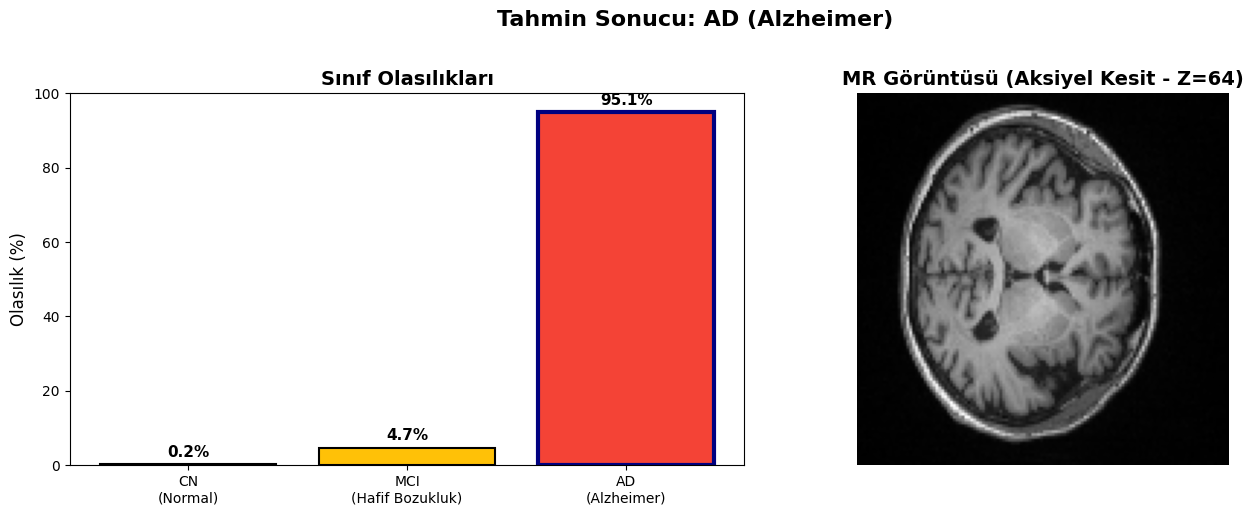

In [ ]:
# Sonuçları görselleştir
import matplotlib.pyplot as plt

try:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # 1. Olasılık dağılımı (Bar Chart)
    ax1 = axes[0]
    class_labels = ['CN\n(Normal)', 'MCI\n(Hafif Bozukluk)', 'AD\n(Alzheimer)']
    colors = ['#4CAF50', '#FFC107', '#F44336']
    bars = ax1.bar(class_labels, probabilities * 100, color=colors, edgecolor='black', linewidth=1.5)
    ax1.set_ylabel('Olasılık (%)', fontsize=12)
    ax1.set_title('Sınıf Olasılıkları', fontsize=14, fontweight='bold')
    ax1.set_ylim(0, 100)
    
    for bar, prob in zip(bars, probabilities):
        height = bar.get_height()
        ax1.annotate(f'{prob*100:.1f}%',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    bars[prediction].set_edgecolor('navy')
    bars[prediction].set_linewidth(3)
    
    # 2. MR görüntüsünün ortadaki kesiti
    ax2 = axes[1]
    mid_slice = mr_data.shape[2] // 2
    ax2.imshow(mr_data[:, :, mid_slice], cmap='gray')
    ax2.set_title(f'MR Görüntüsü (Aksiyel Kesit - Z={mid_slice})', fontsize=14, fontweight='bold')
    ax2.axis('off')
    
    plt.suptitle(f'Tahmin Sonucu: {class_name}', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Görselleştirme hatası: {e}")